# Hedging short-dated options under a Bachelier jump-diffusion: theory

This notebook collects the derivations behind the project. It covers the model, the one-off hedge, Merton's hedge and the variance-optimal (quadratic) hedge, closed forms for Gaussian and mixed-Gaussian jumps, and the four option portfolios studied in the simulations. Every formula that is implemented in `jdhedge` is checked numerically at the end.

Contents:
1. Model
2. The hedging problem
3. One-off hedge
4. Continuous hedging: Merton's hedge and the quadratic hedge
5. Gaussian jumps: closed forms
6. Mixed-Gaussian jumps
7. Portfolios of calls and puts
8. Numerical checks

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy import integrate
from scipy.stats import norm, poisson

sys.path.insert(0, str(Path.cwd().parent))
from jdhedge import Model, PAYOFFS, value_and_delta, quadratic_hedge, simulate_paths, terminal_payoff

## 1. Model

Over a horizon of a day or less, the difference between lognormal and normal dynamics is negligible, so we work with an arithmetic (Bachelier) model. Under the pricing measure,

$$X_t = X_0 + \sigma W_t - \lambda m t + \sum_{i=1}^{N_t} Y_i, \qquad t \in [0, T],$$

where $W$ is a Brownian motion, $N$ a Poisson process with intensity $\lambda$, and the jumps $Y_i$ are i.i.d. with mean $m$ and density $f$, independent of $W$ and $N$. The compensating drift $-\lambda m t$ is Merton's choice of risk-neutral measure: it leaves the diffusion and jump parts unchanged and makes $X$ a martingale. Interest rates are zero.

The variance of $X$ per unit time is

$$q = \sigma^2 + \lambda\, \mathbb{E}[Y^2] = \sigma^2 + \lambda (m^2 + \delta^2)$$

when $Y \sim \mathcal{N}(m, \delta^2)$. We call $\lambda \mathbb{E}[Y^2] / \sigma^2$ the jump share of the variance. Because jump sizes are random, the market made of the underlying alone is incomplete: no strategy in $X$ replicates an option exactly, and the choice of hedge becomes a choice of risk criterion.

A note on time units. Only the products $\lambda T$ (the expected number of jumps over the option's life) and $\sigma^2 T$, $\lambda \delta^2 T$ (variance contributions) matter, so we set $T = 1$ throughout. With $\lambda = 2$, the base case describes an option whose remaining life contains on average two jump events, for instance an expiry on a day with a scheduled announcement, rather than a one-year option.

## 2. The hedging problem

A dealer sells an option with payoff $H(X_T)$ at its model value $V_0 = \mathbb{E}[H(X_T)]$ and trades the underlying with position $\phi_t$. Terminal wealth is

$$W_T = V_0 - H(X_T) + \int_0^T \phi_t \, dX_t .$$

Since $X$ is a martingale, $\mathbb{E}[W_T] = 0$ for any reasonable $\phi$, so minimizing $\mathbb{E}[W_T^2]$ is the same as minimizing the variance of the hedging error. This is the criterion used throughout.

## 3. One-off hedge

Suppose the dealer may trade only once, at a time $\tau \in [0, T)$, and holds $\phi_\tau$ until maturity. With $D_\tau = X_T - X_\tau$,

$$\mathbb{E}[W_T^2] = \mathbb{E}\big[(V_0 - H(X_T))^2\big] - \mathcal{R}, \qquad \mathcal{R} = 2\,\mathbb{E}\big[\phi_\tau (H(X_T) - V_0) D_\tau\big] - \mathbb{E}\big[\phi_\tau^2 D_\tau^2\big],$$

so the hedge should maximize the variance reduction $\mathcal{R}$. Three versions of the problem differ in what is fixed in advance.

In strategy A, both $\tau$ and $\phi$ are constants. Because $\mathbb{E}[D_\tau] = 0$, the constant $V_0$ drops out and $\mathcal{R}_A(\phi) = 2\phi A_\tau - \phi^2 B_\tau$ with $A_\tau = \mathbb{E}[H(X_T) D_\tau]$ and $B_\tau = \mathbb{E}[D_\tau^2]$. Completing the square,

$$\phi_A = \frac{A_\tau}{B_\tau}, \qquad \mathcal{R}_A^* = \frac{A_\tau^2}{B_\tau} \ge 0. \tag{1}$$

In strategy B, the time $\tau$ is fixed but the size may depend on the state $X_\tau = x$. Maximizing pointwise in $x$ gives

$$\phi_B(x) = \frac{a_\tau(x)}{b_\tau}, \qquad a_\tau(x) = \mathbb{E}\big[H(X_T) D_\tau \mid X_\tau = x\big], \qquad \mathcal{R}_B^* = \frac{\mathbb{E}\big[a_\tau(X_\tau)^2\big]}{b_\tau}, \tag{2}$$

where $b_\tau = \mathbb{E}[D_\tau^2] = q(T - \tau)$ does not depend on $x$ because $X$ has independent increments. Since $\mathbb{E}[a_\tau(X_\tau)] = A_\tau$, Jensen's inequality gives $\mathcal{R}_B^* \ge \mathcal{R}_A^*$: using the observed state never hurts.

In strategy C, both the time and the size are chosen dynamically, which turns the problem into optimal stopping. It is not treated here.

## 4. Continuous hedging: Merton's hedge and the quadratic hedge

When the position can be adjusted continuously, write $V(t, x) = \mathbb{E}[H(X_T) \mid X_t = x]$. Over $[t, t + dt]$ the hedged position changes by $dV - \phi_t\, dX_t$, whose conditional variance is

$$d\langle V \rangle_t - 2 \phi_t \, d\langle V, X \rangle_t + \phi_t^2 \, d\langle X \rangle_t .$$

Minimizing this at each instant gives $\phi^*_t = d\langle V, X \rangle_t / d\langle X \rangle_t$. For the jump-diffusion,

$$d\langle X \rangle_t = q\, dt, \qquad d\langle V, X \rangle_t = \Big(\sigma^2 V_x(t, X_{t-}) + \lambda \int \big[V(t, X_{t-} + y) - V(t, X_{t-})\big]\, y f(y)\, dy\Big)\, dt,$$

hence the quadratic hedge

$$\phi^*(t, x) = \frac{\sigma^2 V_x(t, x) + \lambda \int \big[V(t, x+y) - V(t, x)\big]\, y f(y)\, dy}{\sigma^2 + \lambda \int y^2 f(y)\, dy}. \tag{3}$$

Merton's hedge is the instantaneous delta $V_x(t, x)$. It is myopic: it neutralizes small moves and ignores what a jump does to the position. Formula (3) is a weighted average of the two sources of risk. The diffusion part is hedged with the local delta, with weight $\sigma^2$. The jump part is hedged with the regression slope of the option's value change on the jump size, with weight $\lambda \mathbb{E}[Y^2]$. When $\lambda = 0$, $\phi^* = V_x$; when $\sigma = 0$, only the jump regression remains.

## 5. Gaussian jumps: closed forms

Let $Y \sim \mathcal{N}(m, \delta^2)$ and $\theta = T - t$. Conditional on $n$ jumps in $(t, T]$, the increment $X_T - X_t$ is Gaussian with

$$\mu_n(\theta) = (n - \lambda\theta)\, m, \qquad v_n(\theta) = \sigma^2 \theta + n \delta^2 .$$

Write $p_n(\theta) = e^{-\lambda\theta} (\lambda\theta)^n / n!$ and use the Bachelier building block

$$B(a, v) = \mathbb{E}\big[(a + \sqrt{v} Z)^+\big] = a\, N\!\Big(\frac{a}{\sqrt{v}}\Big) + \sqrt{v}\, n\!\Big(\frac{a}{\sqrt{v}}\Big), \qquad \partial_a B(a, v) = N\!\Big(\frac{a}{\sqrt{v}}\Big),$$

with $N$ and $n$ the standard normal cdf and pdf. A call with strike $K$ is then a Poisson mixture of Bachelier prices,

$$V(t, x) = \sum_{n \ge 0} p_n(\theta)\, \Pi_n(t, x), \qquad \Pi_n(t, x) = B\big(x + \mu_n - K,\ v_n\big), \tag{4}$$

and Merton's hedge is $V_x = \sum_n p_n \Delta_n$ with $\Delta_n = N\big((x + \mu_n - K)/\sqrt{v_n}\big)$.

### The jump integral

Two facts reduce the integral in (3) to a finite sum. Stein's lemma for $Y \sim \mathcal{N}(m, \delta^2)$ states $\mathbb{E}[g(Y) Y] = m\, \mathbb{E}[g(Y)] + \delta^2\, \mathbb{E}[g'(Y)]$. And averaging a component price over one additional jump adds $m$ to its mean and $\delta^2$ to its variance, so $\mathbb{E}[\Pi_n(t, x + Y)] = \Pi_{n+1}(t, x)$. Together,

$$\int \big[V(t, x+y) - V(t, x)\big]\, y f(y)\, dy = \sum_{n \ge 0} p_n(\theta) \Big[m \big(\Pi_{n+1} - \Pi_n\big) + \delta^2 \Delta_{n+1}\Big]. \tag{5}$$

This holds for any payoff whose components are Gaussian expectations, which covers every portfolio of calls and puts. It is what `jdhedge.quadratic_hedge` implements.

### Centered jumps and a single call

For $m = 0$ the quadratic hedge of a call becomes

$$\phi^*(t, x) = \sum_{n \ge 0} p_n(\theta)\, \frac{\sigma^2\, N\big(\tfrac{x - K}{\sqrt{v_n}}\big) + \lambda\delta^2\, N\big(\tfrac{x - K}{\sqrt{v_{n+1}}}\big)}{\sigma^2 + \lambda\delta^2}. \tag{6}$$

Its properties follow directly from the formula.

1. It lies in $[0, 1]$ and is increasing in $x$, from 0 as $x \to -\infty$ to 1 as $x \to \infty$.
2. Without jumps ($\lambda = 0$ or $\delta = 0$) it reduces to Merton's delta.
3. The correction moves the hedge toward one half. Because $v_{n+1} > v_n$, the argument $(x-K)/\sqrt{v_{n+1}}$ is closer to zero than $(x-K)/\sqrt{v_n}$. Out of the money ($x < K$) this raises the hedge above Merton's, since a jump could carry the option into the money. In the money ($x > K$) it lowers it, since a jump could carry it out. At $x = K$ both terms equal one half and the hedges agree.
4. Close to expiry the series concentrates on $n = 0$ and, for $x \neq K$,
$$\lim_{\theta \to 0} \phi^*(t, x) = \frac{\sigma^2\, \mathbf{1}_{\{x > K\}} + \lambda\delta^2\, N\big(\tfrac{x-K}{\delta}\big)}{\sigma^2 + \lambda\delta^2}.$$
Merton's hedge becomes a step function at the strike, while the quadratic hedge keeps a smooth component of width $\delta$. This is the regime of 0DTE options, where the difference between the two hedges is largest.

### One-off hedge of a call

With $m = 0$ and $X_0 = 0$, the increment $X_T - X_s$ given $X_T$ has conditional mean $\frac{T-s}{T} X_T$, because $X$ has i.i.d. increments. Therefore

$$A_s = \mathbb{E}\big[(X_T - K)^+ (X_T - X_s)\big] = \frac{T - s}{T}\, G, \qquad G = \mathbb{E}\big[X_T (X_T - K)^+\big] = \sum_{k \ge 0} p_k(T)\, v_k(T)\, N\!\Big(\frac{-K}{\sqrt{v_k(T)}}\Big),$$

where the last step is Stein's lemma applied to $X_T \sim \mathcal{N}(0, v_k(T))$ given $k$ jumps. With $B_s = q (T - s)$, equation (1) gives $\phi_A = G / (qT)$ and $\mathcal{R}_A(s) = (T - s)\, G^2 / (q T^2)$, which is largest for $s = 0$:

$$s_A^* = 0, \qquad \phi_A^* = \frac{G}{qT}, \qquad \mathcal{R}_A^* = \frac{G^2}{qT}. \tag{7}$$

For strategy B, conditioning on $X_s = x$ and using $m\, p_m(h) = \lambda h\, p_{m-1}(h)$ with $h = T - s$,

$$\phi_B(s, x) = \frac{\sigma^2 \sum_m p_m(h)\, N\big(\tfrac{x - K}{\sqrt{v_m(h)}}\big) + \lambda\delta^2 \sum_m p_m(h)\, N\big(\tfrac{x - K}{\sqrt{v_{m+1}(h)}}\big)}{q},$$

which is exactly the continuous-time quadratic hedge (6) evaluated at time $s$. The optimal time $s_B^*$ maximizes $\mathbb{E}[a_s(X_s)^2] / (qh)$ and has no closed form; note that $\mathcal{R}_B(0) = \mathcal{R}_A^*$ and $\mathcal{R}_B(s) \to 0$ as $s \to T$.

### The parabola

For $H(x) = x^2$, $V(t, x) = x^2 + q\theta$ and $V_x = 2x$. The jump integral is $\int (2xy + y^2)\, y f(y)\, dy = 2x\, \mathbb{E}[Y^2] + \mathbb{E}[Y^3]$, so

$$\phi^*(t, x) = 2x + \frac{\lambda\, \mathbb{E}[Y^3]}{q}, \qquad \mathbb{E}[Y^3] = m^3 + 3 m \delta^2 .$$

The two hedges coincide when the jumps are symmetric, and skewed jumps shift the quadratic hedge by a constant. The parabola is a useful test case for the code because everything is explicit.

## 6. Mixed-Gaussian jumps

If $Y$ is a mixture $\sum_{i=1}^M w_i\, \mathcal{N}(m_i, \delta_i^2)$, the jump process splits into $M$ independent compound Poisson processes with intensities $\lambda_i = \lambda w_i$. With a multi-index $\mathbf{k} = (k_1, \dots, k_M)$ of jump counts,

$$p_{\mathbf{k}}(\theta) = \prod_{i} e^{-\lambda_i\theta} \frac{(\lambda_i\theta)^{k_i}}{k_i!}, \qquad \mu_{\mathbf{k}} = \sum_i (k_i - \lambda_i\theta)\, m_i, \qquad v_{\mathbf{k}} = \sigma^2\theta + \sum_i k_i \delta_i^2,$$

and the variance rate is $q = \sigma^2 + \sum_i \lambda_i (m_i^2 + \delta_i^2)$. Applying (5) component by component,

$$\phi^*(t, x) = \frac{1}{q}\Big[\sigma^2 \sum_{\mathbf{k}} p_{\mathbf{k}} \Delta_{\mathbf{k}} + \sum_{i=1}^M \lambda_i \sum_{\mathbf{k}} p_{\mathbf{k}} \Big(m_i \big(\Pi_{\mathbf{k} + \mathbf{e}_i} - \Pi_{\mathbf{k}}\big) + \delta_i^2\, \Delta_{\mathbf{k} + \mathbf{e}_i}\Big)\Big],$$

with $\mathbf{e}_i$ the $i$-th unit vector. For the parabola this gives $\phi^* = 2x + \sum_i \lambda_i (m_i^3 + 3 m_i \delta_i^2) / q$. A mixture allows asymmetric jump risk, for example rare large down-jumps together with frequent small up-jumps, while keeping every quantity in closed form.

## 7. Portfolios of calls and puts

Any payoff $H(x) = \sum_j w_j (x - K_j)^+ + \sum_j w'_j (L_j - x)^+$ inherits the structure above: $\Pi_n$ and $\Delta_n$ are sums of Bachelier call and put components, and (4), (5) apply unchanged. The simulations use four portfolios, with $K = 0.3$.

1. ATM straddle, $H(x) = |x|$. The payoff and the price are even in $x$, so for centered jumps both hedges are odd in $x$ and vanish at $x = 0$. This has a consequence for the simulations: a straddle hedged only once at $t = 0$ from $X_0 = 0$ is not hedged at all.
2. W-profile, $H(x) = (-K - x)^+ - \alpha |x| + (x - K)^+$ with $\alpha = 1/2$: long wings and a short straddle, with kinks at $-K$, $0$ and $K$.
3. Risk reversal, $H(x) = (x - K)^+ - (-K - x)^+$: long an out-of-the-money call and short an out-of-the-money put. The payoff is odd, so the hedges are even in $x$. They are positive everywhere, smallest between the strikes and close to one in the wings.
4. Call ratio spread, $H(x) = 3(x - K)^+ - (x + K)^+$. The payoff slope is 0 below $-K$, $-1$ between the strikes (only the short call is in the money) and $+2$ above $K$, so the delta changes sign. Near the sign change the quadratic hedge, which averages the delta over possible jumps, can have the opposite sign to Merton's hedge. Notebook 02 studies this.

The figure shows value and hedges halfway to maturity for the base parameters.

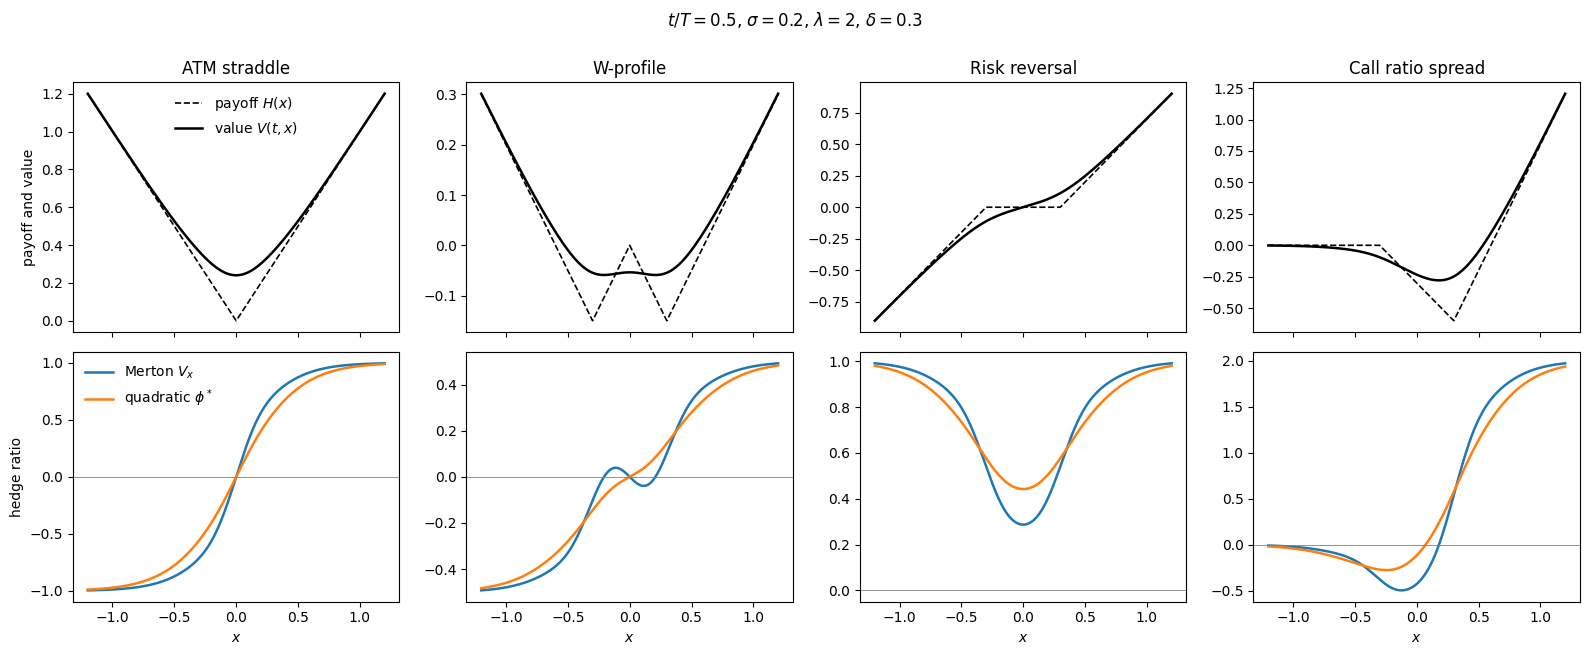

In [2]:
T = 1.0
base = Model(sigma=0.20, lam=2.0, m=0.0, delta=0.30)
x = np.linspace(-1.2, 1.2, 601)
t = 0.5

fig, axes = plt.subplots(2, 4, figsize=(16, 6.5), sharex=True)
for j, (name, payoff) in enumerate(PAYOFFS.items()):
    value, merton = value_and_delta(t, x, T, base, payoff)
    quad = quadratic_hedge(t, x, T, base, payoff)
    axes[0, j].plot(x, terminal_payoff(x, payoff), "k--", lw=1.2, label="payoff $H(x)$")
    axes[0, j].plot(x, value, "k", lw=1.8, label="value $V(t,x)$")
    axes[0, j].set_title(name)
    axes[1, j].plot(x, merton, lw=1.8, label="Merton $V_x$")
    axes[1, j].plot(x, quad, lw=1.8, label=r"quadratic $\phi^*$")
    axes[1, j].axhline(0, color="grey", lw=0.6)
    axes[1, j].set_xlabel("$x$")
axes[0, 0].legend(frameon=False)
axes[1, 0].legend(frameon=False)
axes[0, 0].set_ylabel("payoff and value")
axes[1, 0].set_ylabel("hedge ratio")
fig.suptitle(rf"$t/T = {t}$, $\sigma = {base.sigma}$, $\lambda = {base.lam:g}$, $\delta = {base.delta}$", y=1.0)
fig.tight_layout()
plt.show()

## 8. Numerical checks

Each check compares an implemented formula with an independent computation.

In [3]:
model = Model(sigma=0.20, lam=2.0, m=0.10, delta=0.30)
t, x0 = 0.4, 0.1

# (5): series form of the jump integral against direct quadrature, for every payoff.
for name, payoff in PAYOFFS.items():
    v0, vx = value_and_delta(t, x0, T, model, payoff)
    density = norm(model.m, model.delta).pdf
    integrand = lambda y: (value_and_delta(t, x0 + y, T, model, payoff)[0] - v0) * y * density(y)
    jump_integral = integrate.quad(integrand, -3, 3, limit=200)[0]
    direct = (model.sigma**2 * vx + model.lam * jump_integral) / model.variance_rate
    print(f"{name:18s} series {float(quadratic_hedge(t, x0, T, model, payoff)):.10f}   quadrature {direct:.10f}")

ATM straddle       series 0.3589468188   quadrature 0.3589468188


W-profile          series 0.1036413531   quadrature 0.1036413531


Risk reversal      series 0.5061442792   quadrature 0.5061442792


Call ratio spread  series 0.2954033209   quadrature 0.2954033209


In [4]:
# (4): Poisson-mixture prices against Monte Carlo from the exact path simulator.
rng = np.random.default_rng(12)
x_T = simulate_paths(model, T, 1, 4_000_000, rng)[:, -1]
for name, payoff in PAYOFFS.items():
    h = terminal_payoff(x_T, payoff)
    mc, se = h.mean(), h.std() / np.sqrt(len(h))
    exact = float(value_and_delta(0.0, 0.0, T, model, payoff)[0])
    print(f"{name:18s} closed form {exact:.5f}   Monte Carlo {mc:.5f} +/- {1.96 * se:.5f}")

ATM straddle       closed form 0.37684   Monte Carlo 0.37689 +/- 0.00031


W-profile          closed form -0.03417   Monte Carlo -0.03418 +/- 0.00011


Risk reversal      closed form 0.01832   Monte Carlo 0.01825 +/- 0.00029
Call ratio spread  closed form -0.10911   Monte Carlo -0.10905 +/- 0.00037


In [5]:
# (7): one-off hedge of a call at s = 0, closed form against Monte Carlo.
centered = Model(sigma=0.20, lam=2.0, m=0.0, delta=0.30)
K = 0.3
k = np.arange(80)
v_k = centered.sigma**2 * T + k * centered.delta**2
G = np.sum(poisson.pmf(k, centered.lam * T) * v_k * norm.cdf(-K / np.sqrt(v_k)))
phi_A = G / (centered.variance_rate * T)
R_A = G**2 / (centered.variance_rate * T)

x_T = simulate_paths(centered, T, 1, 2_000_000, np.random.default_rng(1))[:, -1]
h = np.maximum(x_T - K, 0.0)
phi_mc = np.mean(h * x_T) / np.mean(x_T**2)
R_mc = h.var() - (h - phi_mc * x_T).var()
print(f"phi_A: closed form {phi_A:.5f}, Monte Carlo {phi_mc:.5f}")
print(f"R_A:   closed form {R_A:.5f}, Monte Carlo {R_mc:.5f}")

phi_A: closed form 0.27491, Monte Carlo 0.27540
R_A:   closed form 0.01663, Monte Carlo 0.01666


In [6]:
# Parabola: the quadratic hedge is 2x + lambda E[Y^3] / q.
parabola_skew = model.lam * (model.m**3 + 3 * model.m * model.delta**2) / model.variance_rate
xs = np.array([-0.5, 0.0, 0.7])
dens = norm(model.m, model.delta).pdf
num = [model.sigma**2 * 2 * xi + model.lam * integrate.quad(lambda y: (2 * xi * y + y**2) * y * dens(y), -4, 4)[0]
       for xi in xs]
print("formula   ", 2 * xs + parabola_skew)
print("quadrature", np.array(num) / model.variance_rate)

formula    [-0.76666667  0.23333333  1.63333333]
quadrature [-0.76666667  0.23333333  1.63333333]
